# 04 · Sensores, cálculos, JSON y pantalla

[Índice](00_indice_y_recorrido.ipynb) · [Anterior](03_arranque_conexion_y_tiempo.ipynb) · [Siguiente](05_csv_persistencia_y_confirmaciones.ipynb)

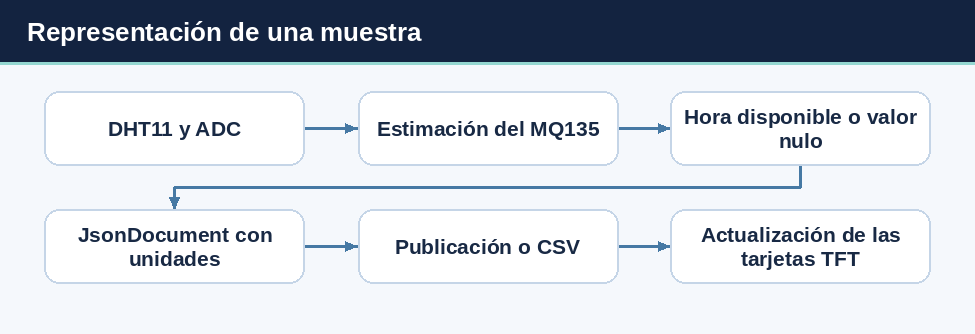

## `sampleAndPublish`


**Parámetros:** ninguno. **Retorno:** `void`. Orquesta una lectura completa.
Lee temperatura (°C) y humedad (%RH) del DHT11, las pasa como argumentos a `readGasPpm` para la
compensación ambiental y obtiene la hora. Crea un `JsonDocument` local y lo llena por referencia.
`serializeJson(document,json)` convierte la estructura a texto listo para transmitir.

Si MQTT no está conectado o `publish(topic,payload)` devuelve falso, guarda CSV. Esa sobrecarga
de PubSubClient publica con QoS 0: verdadero no garantiza recepción por el broker. El resultado
no cambia el formato de mediciones. Finalmente actualiza la pantalla aunque no haya red.

```cpp
void sampleAndPublish() {
    const float temperature = dhtSensor.readTemperature();
    const float humidity = dhtSensor.readHumidity();
    const float gasPpm = readGasPpm(temperature, humidity);
    const String timestamp = getCurrentTimestamp();

    JsonDocument document;
    buildMeasurementJson(document, timestamp, temperature, humidity, gasPpm);
    String json;
    serializeJson(document, json);
    if (!mqttClient.connected() || !mqttClient.publish(processedTopic.c_str(), json.c_str())) {
        saveMeasurementCsv(timestamp, temperature, humidity, gasPpm);
    }

    updateDisplay(temperature, humidity, gasPpm);
}
```

## `readGasPpm`


**Parámetros:** `float temperature` en °C y `float humidity` en %RH.
**Retorno:** `float` ppm estimadas, o `NAN` si no se puede obtener un resultado válido.

1. Rechaza temperatura/humedad no finitas y humedad fuera de 0…100.
2. Suma 32 lecturas `analogReadMilliVolts(PIN_MQ135)`, separadas por `delay(2)`.
   Divide entre `32*1000` para promediar y convertir mV a V.
3. Multiplica el voltaje ADC por 2 para reconstruir AO, suponiendo un divisor 10k/10k.
   Rechaza ADC inferior a 0.15 V, ADC a partir de 3 V y AO a partir de 5 V.
4. Calcula compensación empírica `0.00035*T² - 0.02718*T + 1.39538 - 0.0018*(H−33)`.
5. La carga efectiva es `2*20/22` kOhm: RL 2k en paralelo con la rama externa de 20k.
6. Calcula resistencia compensada `(5/AO−1)*RL_efectiva/factor`. Descarta resultados no finitos,
   no positivos o factor no positivo.
7. Acumula 30 muestras válidas. Antes de la número 30 devuelve NAN y muestra el avance.
8. Estima `R0 = promedio(Rs_compensada)/(450/A)^(1/B)`.
9. Estima `ppm = A*(Rs_compensada/R0)^B`. Devuelve NAN si no es finita y positiva.

`powf(base,exponente)` calcula potencia con `float`; no es una multiplicación. La referencia
supone 450 ppm y requiere un sensor estabilizado; el programa no implementa un período automático
de calentamiento ni mide esa concentración real. El MQ135 responde a varios gases: estas ppm no
son una medición selectiva de CO2. `calibrate=false` describe esta limitación.

En algunos retornos tempranos el texto de estado conserva su valor anterior; el número inválido
sí se comunica como NAN/null. La referencia se reinicia con la placa. Los límites ADC son
condiciones del cálculo, no protecciones eléctricas.

```cpp
float readGasPpm(float temperature, float humidity) {
    if (!isfinite(temperature) || !isfinite(humidity) || humidity < 0 || humidity > 100) {
        return NAN;
    }
    float adcVoltage = 0;
    for (int i = 0; i < ADC_SAMPLE_COUNT; ++i) {
        adcVoltage += analogReadMilliVolts(PIN_MQ135);
        delay(2);
    }
    adcVoltage /= ADC_SAMPLE_COUNT * 1000.0f;
    const float sensorOutputVoltage = adcVoltage * 2; // Divisor externo 10k / 10k.
    if (adcVoltage < 0.15f || adcVoltage >= 3 || sensorOutputVoltage >= MQ_SUPPLY_VOLTAGE) {
        gasSensorStatus = "Error ADC";
        return NAN;
    }
    const float environmentalCorrection = 0.00035f * temperature * temperature -
                                          0.02718f * temperature + 1.39538f -
                                          0.0018f * (humidity - 33);
    // La carga efectiva incluye el divisor externo en paralelo con RL (2 kOhm).
    const float effectiveLoadResistance = (2.0f * 20.0f) / 22.0f;
    const float correctedResistance = (MQ_SUPPLY_VOLTAGE / sensorOutputVoltage - 1) *
                                      effectiveLoadResistance / environmentalCorrection;
    if (!isfinite(correctedResistance) || correctedResistance <= 0 ||
        environmentalCorrection <= 0) {
        return NAN;
    }
    // Estimar R0 a partir de 30 muestras y una referencia supuesta de 450 ppm.
    if (referenceCount < REFERENCE_SAMPLE_COUNT) {
        referenceResistanceSum += correctedResistance;
        ++referenceCount;
        gasSensorStatus =
            "Referencia " + String(referenceCount) + "/" + String(REFERENCE_SAMPLE_COUNT);
        if (referenceCount < REFERENCE_SAMPLE_COUNT) {
            return NAN;
        }
        referenceResistance = (referenceResistanceSum / REFERENCE_SAMPLE_COUNT) /
                              powf(MQ_REFERENCE_PPM / MQ_CURVE_A, 1.0f / MQ_CURVE_B);
    }
    const float ppm = MQ_CURVE_A * powf(correctedResistance / referenceResistance, MQ_CURVE_B);
    gasSensorStatus = "PPM estimadas";
    return isfinite(ppm) && ppm > 0 ? ppm : NAN;
}
```

## `formatCsvNumber`


**Parámetro:** `float value`. **Retorno:** `String` con dos decimales si es finito, o cadena vacía.
`String(value,2)` redondea la representación textual; no aumenta precisión del sensor.
Los campos CSV vacíos se convierten a `null` en el conversor. La TFT aplica su propio formato para cada tarjeta.

```cpp
String formatCsvNumber(float value) {
    return isfinite(value) ? String(value, 2) : "";
}
```

## `buildMeasurementJson`


**Parámetros:** `JsonDocument &document`, destino modificable; `const String &timestamp`, fecha
sin copiar; `float temperature`, `float humidity`, `float gasPpm`, valores de la lectura.
**Retorno:** `void`; el resultado queda dentro del documento recibido.

Escribe device_id y timestamp. Si fecha está vacía asigna `nullptr`, que ArduinoJson representa
como `null`. Crea `measurements` con `to<JsonObject>()`. Los arreglos `names`, `units` y `values`
relacionan por posición temperatura, humedad y gas. La variable local `measurement` representa
cada objeto anidado. El índice 2 usa MQ135; los dos primeros DHT11. Valores no finitos se reemplazan
por null. El gas siempre agrega el booleano `calibrate=false`.

Los nombres exactos y las unidades son parte del contrato que debe reproducir Python. `calibrate`
es la clave del proyecto aunque en otros contextos se use otro nombre. No se agrega ID de registro
al JSON final: el ID interno se usa para confirmar CSV.

```cpp
void buildMeasurementJson(JsonDocument &document, const String &timestamp, float temperature,
                          float humidity, float gasPpm) {
    document["device_id"] = DEVICE_ID;
    if (timestamp.isEmpty()) {
        document["timestamp"] = nullptr;
    } else {
        document["timestamp"] = timestamp;
    }
    JsonObject measurements = document["measurements"].to<JsonObject>();
    const char *names[] = {"temperature", "humidity", "gas"};
    const char *units[] = {"°C", "%RH", "ppm"};
    float values[] = {temperature, humidity, gasPpm};
    for (int i = 0; i < 3; ++i) {
        JsonObject measurement = measurements[names[i]].to<JsonObject>();
        measurement["sensor"] = i == 2 ? "MQ135" : "DHT11";
        if (isfinite(values[i])) {
            measurement["value"] = values[i];
        } else {
            measurement["value"] = nullptr;
        }
        measurement["unit"] = units[i];
    }
    measurements["gas"]["calibrate"] = false;
}
```

## `updateDisplay`

La función recibe las tres mediciones como `float`. Conserva el texto anterior de cada tarjeta en un arreglo `static`. En cada muestra formatea temperatura y humedad con un decimal y gas sin decimales. Para concentraciones muy altas usa notación científica. Muestra `--` cuando el valor no es finito.

`MR_DATUM` alinea el valor por el centro del borde derecho y el relleno borra el área del texto anterior. El estado del MQ135 se actualiza por separado. El [notebook de la TFT](07_pantalla_st7789.ipynb) explica los iconos, el reloj, la paleta y el pie de conexión.

```cpp
void updateDisplay(float temperature, float humidity, float gasPpm) {
    static String previousValues[METRIC_COUNT];
    static String previousGasStatus;
    const float readings[METRIC_COUNT] = {temperature, humidity, gasPpm};
    const int valueRight = display.width() - DISPLAY_MARGIN - 50;

    display.startWrite();
    display.setTextColor(TFT_WHITE, CARD_BG);
    display.setTextDatum(MR_DATUM);
    display.setTextPadding(VALUE_WIDTH);
    for (int metric = 0; metric < METRIC_COUNT; ++metric) {
        const float reading = readings[metric];
        String value = "--";
        if (isfinite(reading)) {
            if (metric == GAS && reading >= 99999.5f) {
                char scientific[16];
                snprintf(scientific, sizeof(scientific), "%.0e", static_cast<double>(reading));
                value = scientific;
            } else {
                value = String(reading, metric == GAS ? 0 : 1);
            }
        }
        if (value != previousValues[metric]) {
            display.drawString(value, valueRight, cardCenter(metric), 4);
            previousValues[metric] = value;
        }
    }

    if (gasSensorStatus != previousGasStatus) {
        display.setTextColor(SECONDARY_TEXT, CARD_BG);
        display.setTextDatum(ML_DATUM);
        display.setTextPadding(valueRight - VALUE_WIDTH - METRIC_LABEL_X);
        display.drawString(gasSensorStatus, METRIC_LABEL_X, cardCenter(GAS) + 8, 2);
        previousGasStatus = gasSensorStatus;
    }
    display.endWrite();
}
```

### Ejemplo del contrato JSON

```json
{
  "device_id": "ESP32_S3_0001",
  "timestamp": "2026-11-20T14:30:00-06:00",
  "measurements": {
    "temperature": {"sensor": "DHT11", "value": 25.0, "unit": "°C"},
    "humidity": {"sensor": "DHT11", "value": 67.5, "unit": "%RH"},
    "gas": {"sensor": "MQ135", "value": 89.2, "unit": "ppm", "calibrate": false}
  }
}
```

JSON no permite una coma después del último campo ni `NaN` numérico estándar.
`null` representa un dato ausente o inválido; 0 representaría una medición válida de cero.

In [ ]:
# Ejercicio aislado: calcular la curva con una relación de resistencias supuesta.
a = 110.47
b = -2.862
reference_ppm = 450.0
assumed_average_resistance = 20.0  # kOhm, ejemplo matemático, no lectura real
r0 = assumed_average_resistance / (reference_ppm / a) ** (1.0 / b)
ppm = a * (assumed_average_resistance / r0) ** b
assert abs(ppm - reference_ppm) < 1e-6
print(f"R0 de ejemplo: {r0:.4f} kOhm; ppm: {ppm:.2f}")

[Índice](00_indice_y_recorrido.ipynb) · [Anterior](03_arranque_conexion_y_tiempo.ipynb) · [Siguiente](05_csv_persistencia_y_confirmaciones.ipynb)